# Rank-k SVD Compression of Images and Network Weights
Muhammad Zain Hassan · 26i-8015 · MSDS 1A · Mathematical and Statistical Foundations for Data Science, Fall 2026

**Research question:** how does the retained rank k change reconstruction error and classification accuracy when SVD is applied
(A) to the images and (B) to the first-layer weight matrix of a small trained network?

Set `DATASET = "fashion"` for Fashion-MNIST (OpenML, 50k/10k/10k split) or `"digits"` for the UCI digits fallback (60/20/20 split).
Only validation numbers are reported here. The test set is held back for the final paper.

In [1]:
DATASET = "digits"   # "fashion" or "digits"
SEED = 42
import platform, numpy as np, sklearn, matplotlib
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.neural_network import MLPClassifier
import warnings; warnings.filterwarnings("ignore")
print("python", platform.python_version(), "| numpy", np.__version__, "| sklearn", sklearn.__version__)

python 3.13.18 | numpy 2.5.3 | sklearn 1.9.1


## 1. Load data and split (train / validation / test)

In [2]:
if DATASET == "fashion":
    from sklearn.datasets import fetch_openml
    X, y = fetch_openml("Fashion-MNIST", version=1, return_X_y=True, as_frame=False, parser="auto")
    X = X.astype(np.float64) / 255.0; y = y.astype(int)
    X_tr, y_tr = X[:50000], y[:50000]
    X_va, y_va = X[50000:60000], y[50000:60000]
    X_te, y_te = X[60000:], y[60000:]
    KS = [0, 1, 2, 5, 10, 20, 50, 100, 200]
else:
    from sklearn.datasets import load_digits
    d = load_digits(); X = d.data / 16.0; y = d.target
    X_tr, X_tmp, y_tr, y_tmp = train_test_split(X, y, test_size=0.4, random_state=SEED, stratify=y)
    X_va, X_te, y_va, y_te = train_test_split(X_tmp, y_tmp, test_size=0.5, random_state=SEED, stratify=y_tmp)
    KS = [0, 1, 2, 5, 10, 20, 50]
print("train", X_tr.shape, "| val", X_va.shape, "| test", X_te.shape, "(test not used)")

train (1078, 64) | val (359, 64) | test (360, 64) (test not used)


## 2. SVD of the centred training matrix
X_c = U Σ Vᵀ. Rank-k reconstruction X_k = U_k Σ_k V_kᵀ. Eckart–Young: ‖X_c − X_k‖²_F = Σ_{i>k} σᵢ².
The mean and the SVD are fitted on training data only (no leakage).

In [3]:
mu = X_tr.mean(axis=0)
U, S, Vt = np.linalg.svd(X_tr - mu, full_matrices=False)
energy = np.cumsum(S**2) / np.sum(S**2)
def evr(k): return 0.0 if k == 0 else energy[k-1]
# Eckart-Young check on training data
for k in [5, 10, 20]:
    Xk = (U[:, :k] * S[:k]) @ Vt[:k]
    lhs = np.sum((X_tr - mu - Xk)**2); rhs = np.sum(S[k:]**2)
    print(f"k={k:3d}  ||Xc-Xk||^2 = {lhs:.6f}   sum_(i>k) s_i^2 = {rhs:.6f}")
print("ranks for 90% image energy:", int(np.searchsorted(energy, 0.90) + 1), "of", len(S))

k=  5  ||Xc-Xk||^2 = 2289.278189   sum_(i>k) s_i^2 = 2289.278189
k= 10  ||Xc-Xk||^2 = 1320.098661   sum_(i>k) s_i^2 = 1320.098661
k= 20  ||Xc-Xk||^2 = 526.927624   sum_(i>k) s_i^2 = 526.927624
ranks for 90% image energy: 21 of 64


## 3. Part A — rank-k reconstruction and logistic regression on k PCA features (validation)

In [4]:
def recon_mse(k, Xs):
    Z = (Xs - mu) @ Vt[:k].T
    return np.mean(((Z @ Vt[:k]) + mu - Xs)**2) if k > 0 else np.mean((mu - Xs)**2)
def clf_acc(k):
    if k == 0: return None
    clf = LogisticRegression(max_iter=2000, random_state=SEED)
    clf.fit((X_tr - mu) @ Vt[:k].T, y_tr)
    return clf.score((X_va - mu) @ Vt[:k].T, y_va)
full_clf = LogisticRegression(max_iter=2000, random_state=SEED).fit(X_tr, y_tr)
A = {k: (evr(k), recon_mse(k, X_va), clf_acc(k)) for k in KS}
A_full = full_clf.score(X_va, y_va)
print("Part A full-pixel validation accuracy:", round(A_full, 3))

Part A full-pixel validation accuracy: 0.958


## 4. Part B — rank-k first-layer weights of a trained network (no retraining)
Network: MLPClassifier, one hidden layer of 256 units, 30 epochs. W (d×256) is replaced by W_k; everything else is frozen.
Stored numbers: k(m+n) instead of mn.

In [5]:
def train_net(seed):
    net = MLPClassifier(hidden_layer_sizes=(256,), max_iter=30, random_state=seed)
    return net.fit(X_tr, y_tr)
def rank_k_acc(net, k):
    W = net.coefs_[0]; Uw, Sw, Vtw = np.linalg.svd(W, full_matrices=False)
    Wk = (Uw[:, :k] * Sw[:k]) @ Vtw[:k]
    saved = net.coefs_[0]; net.coefs_[0] = Wk
    acc = net.score(X_va, y_va); net.coefs_[0] = saved
    return acc, np.linalg.norm(W - Wk) / np.linalg.norm(W)
net = train_net(SEED)
W = net.coefs_[0]; m, n = W.shape
Sw = np.linalg.svd(W, compute_uv=False); ew = np.cumsum(Sw**2) / np.sum(Sw**2)
print("W shape", W.shape, "| ranks for 90% weight energy:", int(np.searchsorted(ew, 0.90) + 1), "of", len(Sw))
B_full = net.score(X_va, y_va)
B = {k: rank_k_acc(net, k) + (k*(m+n)/(m*n),) for k in KS if k > 0}

W shape (64, 256) | ranks for 90% weight energy: 42 of 64


## 5. Results table (validation)

In [6]:
print(f"{'k':>9} {'expl.var':>9} {'recon MSE':>10} {'A acc':>7} {'B acc':>7} {'B rel.err':>9} {'B stored':>9}")
for k in KS:
    ev, mse, a = A[k]
    b = B.get(k)
    print(f"{k:>9} {ev:9.3f} {mse:10.4f} {('%.3f'%a) if a else '—':>7} "
          f"{('%.3f'%b[0]) if b else '—':>7} {('%.2f'%b[1]) if b else '—':>9} {('%.2f'%b[2]) if b else '—':>9}")
print(f"{'full':>9} {1.0:9.3f} {0.0:10.4f} {A_full:7.3f} {B_full:7.3f} {0.0:9.2f} {1.0:9.2f}")

        k  expl.var  recon MSE   A acc   B acc B rel.err  B stored
        0     0.000     0.0728       —       —         —         —
        1     0.147     0.0619   0.357   0.212      0.95      0.02
        2     0.284     0.0518   0.599   0.423      0.92      0.04
        5     0.548     0.0334   0.850   0.883      0.82      0.10
       10     0.739     0.0195   0.936   0.953      0.71      0.20
       20     0.896     0.0081   0.953   0.958      0.57      0.39
       50     1.000     0.0001   0.958   0.950      0.21      0.98
     full     1.000     0.0000   0.958   0.955      0.00      1.00


## 6. Seed robustness for Part B at k = 10

In [7]:
accs = [rank_k_acc(train_net(s), 10)[0] for s in [42, 43, 44]]
print("B at k=10 over seeds 42-44: %.3f ± %.3f" % (np.mean(accs), np.std(accs)))

B at k=10 over seeds 42-44: 0.949 ± 0.003


## 7. Plots: singular value spectrum and accuracy versus k

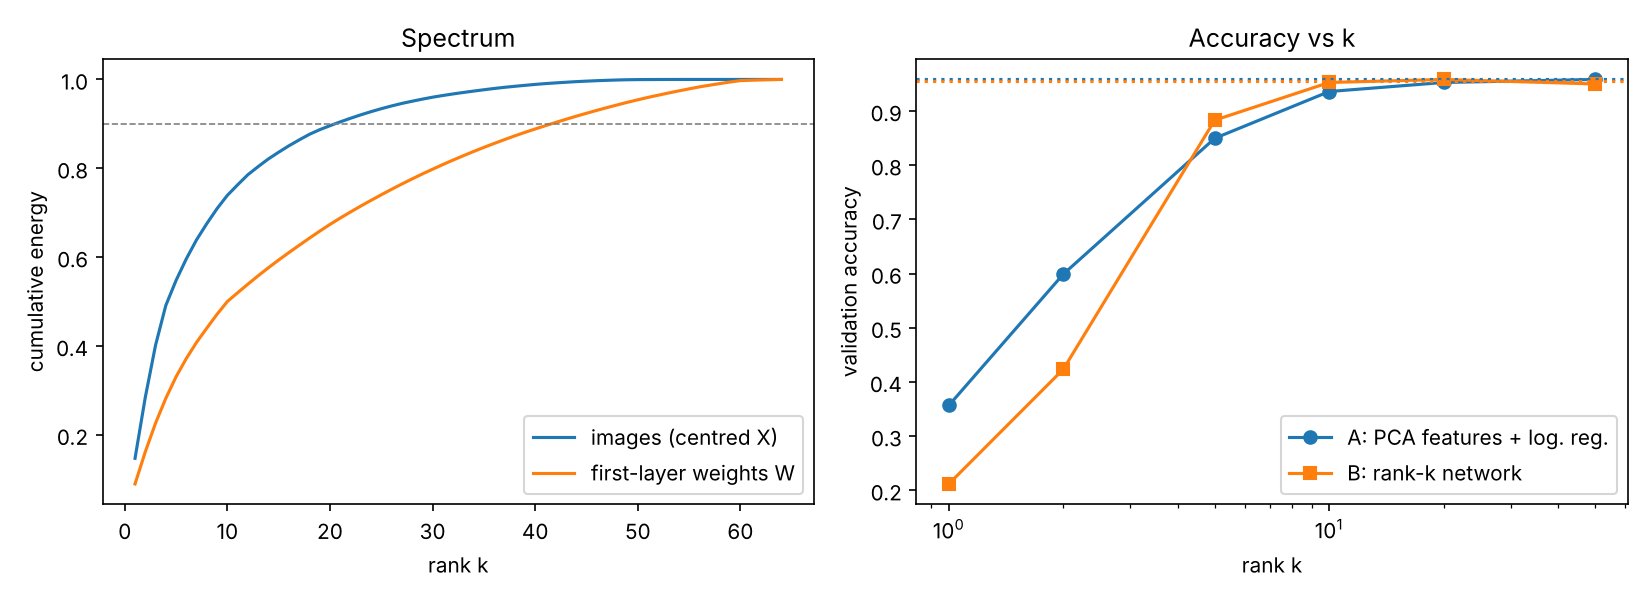

In [8]:
fig, ax = plt.subplots(1, 2, figsize=(11, 4))
ax[0].plot(np.arange(1, len(energy)+1), energy, label="images (centred X)")
ax[0].plot(np.arange(1, len(ew)+1), ew, label="first-layer weights W")
ax[0].axhline(0.9, ls="--", c="gray", lw=0.8)
ax[0].set_xlabel("rank k"); ax[0].set_ylabel("cumulative energy"); ax[0].legend(); ax[0].set_title("Spectrum")
ks = [k for k in KS if k > 0]
ax[1].plot(ks, [A[k][2] for k in ks], "o-", label="A: PCA features + log. reg.")
ax[1].plot(ks, [B[k][0] for k in ks], "s-", label="B: rank-k network")
ax[1].axhline(A_full, ls=":", c="C0"); ax[1].axhline(B_full, ls=":", c="C1")
ax[1].set_xscale("log"); ax[1].set_xlabel("rank k"); ax[1].set_ylabel("validation accuracy"); ax[1].legend(); ax[1].set_title("Accuracy vs k")
plt.tight_layout(); plt.savefig(f"results_{DATASET}.png", dpi=150); plt.show()